In [1]:
#%pip install ipykernel requests pandas numpy urllib3 matplotlib seaborn scikit-learn

In [2]:
import warnings
import time
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.linear_model import LinearRegression

warnings.filterwarnings("ignore")
requests.packages.urllib3.disable_warnings()

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["font.size"] = 10

print("Biblioteki załadowane pomyślnie!")

Biblioteki załadowane pomyślnie!


In [3]:
import requests
import pandas as pd
import numpy as np
import urllib3
import ssl
import time
import os
import json
from datetime import date, timedelta
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

# Wyłączenie ostrzeżeń o braku weryfikacji certyfikatu
urllib3.disable_warnings(urllib3.exceptions.InsecureRequestWarning)

SLOWNIK_WOJEWODZTW = {
    "02": "DOLNOŚLĄSKIE", "04": "KUJAWSKO-POMORSKIE", "06": "LUBELSKIE", "08": "LUBUSKIE",
    "10": "ŁÓDZKIE", "12": "MAŁOPOLSKIE", "14": "MAZOWIECKIE", "16": "OPOLSKIE",
    "18": "PODKARPACKIE", "20": "PODLASKIE", "22": "POMORSKIE", "24": "ŚLĄSKIE",
    "26": "ŚWIĘTOKRZYSKIE", "28": "WARMIŃSKO-MAZURSKIE", "30": "WIELKOPOLSKIE", "32": "ZACHODNIOPOMORSKIE"
}

REQUIRED_COLS = [
    "rodzaj-paliwa", "marka", "model",
    "rok-produkcji", "data-pierwszej-rejestracji-w-kraju", "wlasciciel-wojewodztwo",
    "rejestracja-wojewodztwo", "poziom-emisji-co2", "rodzaj-pojazdu", "pojemnosc-skokowa-silnika", "masa-wlasna"
]

# Ile lat wstecz pobieramy dane z API
LATA_WSTECZ = 1
# Katalog cache (każdy województwo+miesiąc to osobny plik, pozwala wznowić pobieranie)
CACHE_DIR = "cache_cepik"
# Po tylu kolejnych nieudanych paczkach przerywamy API i przechodzimy na generator
MAX_KOLEJNYCH_BLEDOW = 20


class WeakDHAdapter(HTTPAdapter):
    def init_poolmanager(self, *args, **kwargs):
        ctx = urllib3.util.ssl_.create_urllib3_context()
        ctx.set_ciphers("DEFAULT:@SECLEVEL=1")
        ctx.check_hostname = False
        ctx.verify_mode = ssl.CERT_NONE
        kwargs["ssl_context"] = ctx
        super().init_poolmanager(*args, **kwargs)


def month_intervals(start: date, end: date):
    """Dzieli zakres dat na przedziały miesięczne w formacie (YYYYMMDD, YYYYMMDD)."""
    cur = start.replace(day=1)
    while cur <= end:
        nxt = (cur.replace(day=28) + timedelta(days=4)).replace(day=1)
        d_od = max(cur, start)
        d_do = min(nxt - timedelta(days=1), end)
        yield d_od.strftime("%Y%m%d"), d_do.strftime("%Y%m%d")
        cur = nxt


def fetch_all_pages(session, base_url, params, opis, sleep=1.0, max_pages=None):
    """Pobiera wszystkie strony (po 500 rekordów) dla jednego zestawu parametrów."""
    rows, page = [], 1
    while max_pages is None or page <= max_pages:
        p = {**params, "page": str(page), "limit": "500"}
        resp = session.get(base_url, params=p, timeout=30, verify=False)

        if resp.status_code == 404:
            break
        resp.raise_for_status()

        try:
            payload = resp.json()
        except ValueError:
            print(f"[API CEPiK] Uszkodzony JSON: {opis}, strona {page} - kończę tę paczkę.")
            break

        data_list = payload.get("data", [])
        if not data_list:
            break

        for item in data_list:
            attr = item.get("attributes", {})
            rows.append({col: attr.get(col, None) for col in REQUIRED_COLS})

        # Koniec, gdy brak linku do następnej strony
        if not payload.get("links", {}).get("next"):
            break

        page += 1
        time.sleep(sleep)
    return rows


def fetch_cepik_ev_project(woj_dict, max_pages=None, fuel_filter=None, lata=LATA_WSTECZ):
    """Pobiera wskazane kolumny z API CEPiK za ostatnie `lata` lat (ze stronicowaniem).
    W razie błędu odpala generator.

    max_pages   - limit stron na paczkę (None = wszystkie)
    fuel_filter - opcjonalny filtr po stronie API, np. {"filter[rodzaj-paliwa]": "EE"}
                  (kod zweryfikuj w /slowniki/rodzaj-paliwa)
    """
    base_url = "https://api.cepik.gov.pl/pojazdy"

    session = requests.Session()
    retries = Retry(total=5, backoff_factor=2, status_forcelist=[429, 500, 502, 503, 504])
    session.mount("https://", WeakDHAdapter(max_retries=retries))

    os.makedirs(CACHE_DIR, exist_ok=True)

    # Zakres dat liczony dynamicznie: ostatnie `lata` lat do dziś
    end = date.today()
    try:
        start = end.replace(year=end.year - lata)
    except ValueError:  # 29 lutego
        start = end.replace(year=end.year - lata, day=28)
    date_intervals = list(month_intervals(start, end))

    records = []
    api_ok = True
    kolejne_bledy = 0

    for kod, nazwa in woj_dict.items():
        if not api_ok:
            break

        for d_od, d_do in date_intervals:
            cache_file = os.path.join(CACHE_DIR, f"{kod}_{d_od}.json")

            # Wznawianie po przerwaniu: jeśli paczka jest już pobrana, bierzemy z dysku
            if os.path.exists(cache_file):
                with open(cache_file, encoding="utf-8") as f:
                    records.extend(json.load(f))
                continue

            params = {
                "wojewodztwo": kod,
                "data-od": d_od,
                "data-do": d_do,
                "typ-daty": "1",
                "tylko-zarejestrowane": "true",
                "pokaz-wszystkie-pola": "true",
            }
            if fuel_filter:
                params.update(fuel_filter)

            try:
                rows = fetch_all_pages(session, base_url, params, f"{nazwa} {d_od}-{d_do}",
                                       max_pages=max_pages)
            except requests.exceptions.HTTPError as e:
                kolejne_bledy += 1
                print(f"[INFO] Błąd HTTP dla {nazwa} ({d_od} - {d_do}): {e} - pomijam paczkę.")
                if kolejne_bledy >= MAX_KOLEJNYCH_BLEDOW:
                    print("[INFO] Zbyt wiele błędów z rzędu. Uruchamiam generator...")
                    api_ok = False
                    break
                continue
            except Exception as e:
                kolejne_bledy += 1
                print(f"[INFO] Problem z połączeniem ({e}) dla {nazwa} ({d_od} - {d_do}) - pomijam paczkę.")
                if kolejne_bledy >= MAX_KOLEJNYCH_BLEDOW:
                    print("[INFO] Zbyt wiele błędów z rzędu. Uruchamiam generator...")
                    api_ok = False
                    break
                continue

            kolejne_bledy = 0

            for row in rows:
                if not row["rejestracja-wojewodztwo"]:
                    row["rejestracja-wojewodztwo"] = nazwa
                row["zrodlo"] = "CEPiK"

            # Zapis do cache (także puste paczki, żeby ich nie pobierać ponownie)
            with open(cache_file, "w", encoding="utf-8") as f:
                json.dump(rows, f, ensure_ascii=False)

            records.extend(rows)
            print(f"[API CEPiK] Pobrano woj.: {nazwa} ({d_od} - {d_do}) | Rekordów: {len(rows)}")

    if len(records) > 5000:
        print(f"[API CEPiK] Łącznie pobrano {len(records)} rekordów z API.")
        return pd.DataFrame(records)

    print("[INFO] Za mało danych z API - używam danych syntetycznych (zrodlo = SYNTETYCZNE).")

    # Fallback: Generator danych
    np.random.seed(42)
    n_records = 15000

    woj_names = list(woj_dict.values())
    woj_weights = [0.09, 0.04, 0.04, 0.02, 0.06, 0.09, 0.20, 0.02, 0.04, 0.02, 0.07, 0.12, 0.02, 0.03, 0.10, 0.04]

    ev_models = {
        "TESLA": ["MODEL 3", "MODEL Y", "MODEL S"],
        "VOLKSWAGEN": ["ID.4", "ID.3", "ID.BUZZ"],
        "KIA": ["EV6", "NIRO EV", "EV9"],
        "HYUNDAI": ["IONIQ 5", "KONA ELECTRIC", "IONIQ 6"],
        "BMW": ["IX3", "I4", "IX"],
        "AUDI": ["Q4 E-TRON", "E-TRON GT"],
        "NISSAN": ["LEAF", "ARIYA"]
    }
    ice_models = {
        "TOYOTA": ["COROLLA", "YARIS", "RAV4", "C-HR"],
        "VOLKSWAGEN": ["GOLF", "PASSAT", "TIGUAN"],
        "SKODA": ["OCTAVIA", "FABIA", "SUPERB"],
        "AUDI": ["A4", "A6", "Q5"],
        "BMW": ["SERIA 3", "SERIA 5", "X5"],
        "OPEL": ["ASTRA", "INSIGNIA", "CORSA"],
        "FORD": ["FOCUS", "MONDEO", "KUGA"]
    }

    tier1_leaders = ["MAZOWIECKIE", "WIELKOPOLSKIE", "DOLNOŚLĄSKIE", "MAŁOPOLSKIE", "POMORSKIE", "ŚLĄSKIE"]
    tier2_mid = ["ŁÓDZKIE", "ZACHODNIOPOMORSKIE", "KUJAWSKO-POMORSKIE", "LUBUSKIE", "OPOLSKIE"]

    rows = []
    years = [2020, 2021, 2022, 2023, 2024, 2025]
    year_probs = [0.11, 0.13, 0.16, 0.18, 0.20, 0.22]

    for _ in range(n_records):
        woj_wlas = np.random.choice(woj_names, p=woj_weights)
        rok_rej = np.random.choice(years, p=year_probs)
        miesiac_rej = np.random.randint(1, 13)

        if np.random.rand() < 0.18 and woj_wlas not in ["MAZOWIECKIE", "WIELKOPOLSKIE"]:
            woj_rej = np.random.choice(["MAZOWIECKIE", "WIELKOPOLSKIE"], p=[0.7, 0.3])
        else:
            woj_rej = woj_wlas

        year_factor = (rok_rej - 2019) ** 1.35
        if woj_wlas in tier1_leaders:
            p_ev = 0.025 + year_factor * 1.6
            p_hyb = 0.18 + year_factor * 2.2
            p_diesel = 0.28
        elif woj_wlas in tier2_mid:
            p_ev = 0.012 + year_factor * 0.9
            p_hyb = 0.13 + year_factor * 1.8
            p_diesel = 0.35
        else:
            p_ev = 0.005 + year_factor * 0.4
            p_hyb = 0.08 + year_factor * 1.2
            p_diesel = 0.44

        p_benzyna = max(0.05, 1.0 - (p_ev + p_hyb + p_diesel))
        probs = np.array([p_ev, p_hyb, p_diesel, p_benzyna])
        probs = probs / probs.sum()

        naped = np.random.choice(["ELEKTRYCZNY", "HYBRYDA", "DIESEL", "BENZYNA"], p=probs)

        if naped == "ELEKTRYCZNY":
            paliwo = "ENERGIA ELEKTRYCZNA"
            paliwo_alt = None
            marka = np.random.choice(list(ev_models.keys()), p=[0.30, 0.18, 0.14, 0.13, 0.10, 0.08, 0.07])
            model = np.random.choice(ev_models[marka])
            wiek = int(np.clip(np.random.exponential(1.8), 0, 9))
            co2 = 0.0
            moc = int(np.random.normal(185, 55))
        elif naped == "HYBRYDA":
            paliwo = "BENZYNA"
            paliwo_alt = "ENERGIA ELEKTRYCZNA"
            marka = np.random.choice(["TOYOTA", "TOYOTA", "KIA", "HYUNDAI", "FORD", "BMW"])
            model = np.random.choice(ice_models.get(marka, ["COROLLA", "YARIS"]))
            wiek = int(np.clip(np.random.normal(3.8, 2.8), 0, 15))
            co2 = round(np.random.normal(96, 16), 1)
            moc = int(np.random.normal(115, 30))
        elif naped == "DIESEL":
            paliwo = "OLEJ NAPĘDOWY"
            paliwo_alt = None
            marka = np.random.choice(["VOLKSWAGEN", "AUDI", "BMW", "OPEL", "FORD", "SKODA"])
            model = np.random.choice(ice_models[marka])
            wiek = int(np.clip(np.random.normal(11.8 if woj_wlas not in tier1_leaders else 9.5, 4.2), 0, 25))
            co2 = round(np.random.normal(152, 26), 1)
            moc = int(np.random.normal(118, 32))
        else:
            paliwo = "BENZYNA"
            paliwo_alt = "GAZ PŁYNNY (LPG)" if np.random.rand() < 0.16 else None
            marka = np.random.choice(list(ice_models.keys()))
            model = np.random.choice(ice_models[marka])
            wiek = int(np.clip(np.random.normal(9.6 if woj_wlas not in tier1_leaders else 7.5, 4.5), 0, 25))
            co2 = round(np.random.normal(136, 22), 1)
            moc = int(np.random.normal(98, 28))

        rok_prod = rok_rej - wiek
        rodzaj_poj = np.random.choice(["SAMOCHÓD OSOBOWY", "CIĄGNIK ROLNICZY", "MOTOCYKL"], p=[0.93, 0.04, 0.03])

        if np.random.rand() < 0.025: rok_prod = np.nan
        if np.random.rand() < 0.03: marka = "VW" if marka == "VOLKSWAGEN" else marka
        if naped == "ELEKTRYCZNY" and np.random.rand() < 0.08: co2 = np.nan
        if np.random.rand() < 0.015: moc = -10

        rows.append({
            "rodzaj-paliwa": paliwo,
            "rodzaj-paliwa-alternatywnego": paliwo_alt,
            "marka": marka,
            "model": model,
            "rok-produkcji": rok_prod,
            "data-pierwszej-rejestracji": f"{rok_rej}-{miesiac_rej:02d}-15",
            "wlasciciel-wojewodztwo": woj_wlas,
            "rejestracja-wojewodztwo": woj_rej,
            "poziom-emisji-co2": co2,
            "moc-netto-silnika": moc,
            "rodzaj-pojazdu": rodzaj_poj,
            "zrodlo": "SYNTETYCZNE"
        })

    return pd.DataFrame(rows)


df_raw = fetch_cepik_ev_project(SLOWNIK_WOJEWODZTW)
print(f"Pobrano łącznie {len(df_raw)} rekordów. Dostępne kolumny:")
print(df_raw.columns.tolist())

# Zapis surowych danych do data/raw/Dane_raw.csv
RAW_DIR = os.path.join("data", "raw")
RAW_PATH = os.path.join(RAW_DIR, "Dane_raw.csv")
os.makedirs(RAW_DIR, exist_ok=True)
df_raw.to_csv(RAW_PATH, index=False, encoding="utf-8-sig")
print(f"Zapisano surowe dane do: {RAW_PATH}")
# display(df_raw.head()) # Odkomentuj jeśli używasz Jupyter/Colab

[API CEPiK] Pobrano woj.: DOLNOŚLĄSKIE (20251119 - 20251130) | Rekordów: 5016
[API CEPiK] Pobrano woj.: DOLNOŚLĄSKIE (20251201 - 20251231) | Rekordów: 13355
[API CEPiK] Pobrano woj.: DOLNOŚLĄSKIE (20260101 - 20260131) | Rekordów: 10702
[API CEPiK] Pobrano woj.: DOLNOŚLĄSKIE (20260201 - 20260228) | Rekordów: 11235
[API CEPiK] Pobrano woj.: DOLNOŚLĄSKIE (20260301 - 20260331) | Rekordów: 15054
[API CEPiK] Pobrano woj.: DOLNOŚLĄSKIE (20260401 - 20260430) | Rekordów: 13931
[API CEPiK] Pobrano woj.: DOLNOŚLĄSKIE (20260501 - 20260531) | Rekordów: 12658
[API CEPiK] Pobrano woj.: DOLNOŚLĄSKIE (20260601 - 20260630) | Rekordów: 14172
[API CEPiK] Pobrano woj.: DOLNOŚLĄSKIE (20260701 - 20260731) | Rekordów: 14045
[API CEPiK] Pobrano woj.: DOLNOŚLĄSKIE (20260801 - 20260831) | Rekordów: 11857
[API CEPiK] Pobrano woj.: DOLNOŚLĄSKIE (20260901 - 20260930) | Rekordów: 13263
[API CEPiK] Pobrano woj.: DOLNOŚLĄSKIE (20261001 - 20261031) | Rekordów: 13151
[API CEPiK] Pobrano woj.: DOLNOŚLĄSKIE (20261101 - 20

In [4]:
display(df_raw.head())

,rodzaj-paliwa,marka,model,rok-produkcji,data-pierwszej-rejestracji-w-kraju,wlasciciel-wojewodztwo,rejestracja-wojewodztwo,poziom-emisji-co2,rodzaj-pojazdu,pojemnosc-skokowa-silnika,masa-wlasna,zrodlo
0,OLEJ NAPĘDOWY,VOLKSWAGEN,GOLF,2012,2025-11-19,None,DOLNOŚLĄSKIE,NaN,SAMOCHÓD OSOBOWY,1598.0,1445,CEPiK
1,BENZYNA,AUDI,TT,2006,2025-11-19,None,DOLNOŚLĄSKIE,NaN,SAMOCHÓD OSOBOWY,1984.0,1355,CEPiK
2,OLEJ NAPĘDOWY,BMW,X5 XDRIVE30D,2025,2025-11-19,None,DOLNOŚLĄSKIE,NaN,SAMOCHÓD OSOBOWY,2993.0,2220,CEPiK
3,OLEJ NAPĘDOWY,FORD,FIESTA,2006,2025-11-19,None,DOLNOŚLĄSKIE,NaN,SAMOCHÓD CIĘŻAROWY,1399.0,1132,CEPiK
4,OLEJ NAPĘDOWY,VOLKSWAGEN,GOLF,2015,2025-11-19,None,DOLNOŚLĄSKIE,NaN,SAMOCHÓD OSOBOWY,1968.0,1528,CEPiK


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Zastąp df_raw swoim wczytanym zbiorem danych z CEPiK
df_clean = df_raw.copy()

print("--- AUDYT JAKOŚCI DANYCH ---")
print(f"Początkowa liczba rekordów: {len(df_clean)}")

# 1. Sprawdzenie braków danych (Nullity Check)
missing_data = df_clean.isnull().sum()
print("\nBraki danych w kolumnach:")
print(missing_data[missing_data > 0])

# 2. Odfiltrowanie tylko samochodów osobowych (usunięcie autobusów, ciężarówek, motocykli)
df_clean = df_clean[df_clean['rodzaj-pojazdu'] == 'SAMOCHÓD OSOBOWY'].copy()

# 3. Konwersja typów i czyszczenie
df_clean['rok-produkcji'] = pd.to_numeric(df_clean['rok-produkcji'], errors='coerce')
df_clean['data-pierwszej-rejestracji-w-kraju'] = pd.to_datetime(df_clean['data-pierwszej-rejestracji-w-kraju'], errors='coerce')
df_clean['pojemnosc-skokowa-silnika'] = pd.to_numeric(df_clean['pojemnosc-skokowa-silnika'], errors='coerce')
df_clean['masa-wlasna'] = pd.to_numeric(df_clean['masa-wlasna'], errors='coerce')

# Usunięcie skrajnych anomalii (np. literówki urzędników w masie i pojemności)
df_clean = df_clean[
    (df_clean['masa-wlasna'] > 500) & (df_clean['masa-wlasna'] < 3500) &
    (df_clean['pojemnosc-skokowa-silnika'] < 7000)
]

# 4. Feature Engineering (Tworzenie nowych cech)
df_clean['rok_rejestracji'] = df_clean['data-pierwszej-rejestracji-w-kraju'].dt.year
df_clean['wiek_pojazdu'] = df_clean['rok_rejestracji'] - df_clean['rok-produkcji']

# Usunięcie aut z ujemnym wiekiem (błędy w bazie CEPiK)
df_clean = df_clean[df_clean['wiek_pojazdu'] >= 0]

# Oflagowanie pochodzenia: "Krajowy" vs "Import"
# (Zakładamy, że auto sprowadzone ma rok pierwszej rejestracji w kraju o ponad rok większy niż rok produkcji)
df_clean['pochodzenie'] = np.where(df_clean['wiek_pojazdu'] > 1, 'Import używany', 'Krajowy (Nowy)')

def uprosc_paliwo(rodzaj):
    if pd.isna(rodzaj): return "Inne"
    if "ENERGIA ELEKTRYCZNA" in rodzaj: return "Elektryczny (BEV)"
    if "OLEJ NAPĘDOWY" in rodzaj: return "Diesel"
    if "BENZYNA" in rodzaj: return "Benzyna"
    return "Inne"

df_clean['Naped'] = df_clean['rodzaj-paliwa'].apply(uprosc_paliwo)

print(f"\nLiczba rekordów po czyszczeniu: {len(df_clean)}")

--- AUDYT JAKOŚCI DANYCH ---
Początkowa liczba rekordów: 2069680

Braki danych w kolumnach:
rodzaj-paliwa                 146934
marka                         114344
model                             28
rok-produkcji                     10
wlasciciel-wojewodztwo       2069680
poziom-emisji-co2            1767605
rodzaj-pojazdu                     7
pojemnosc-skokowa-silnika     209901
dtype: int64

Liczba rekordów po czyszczeniu: 1394008


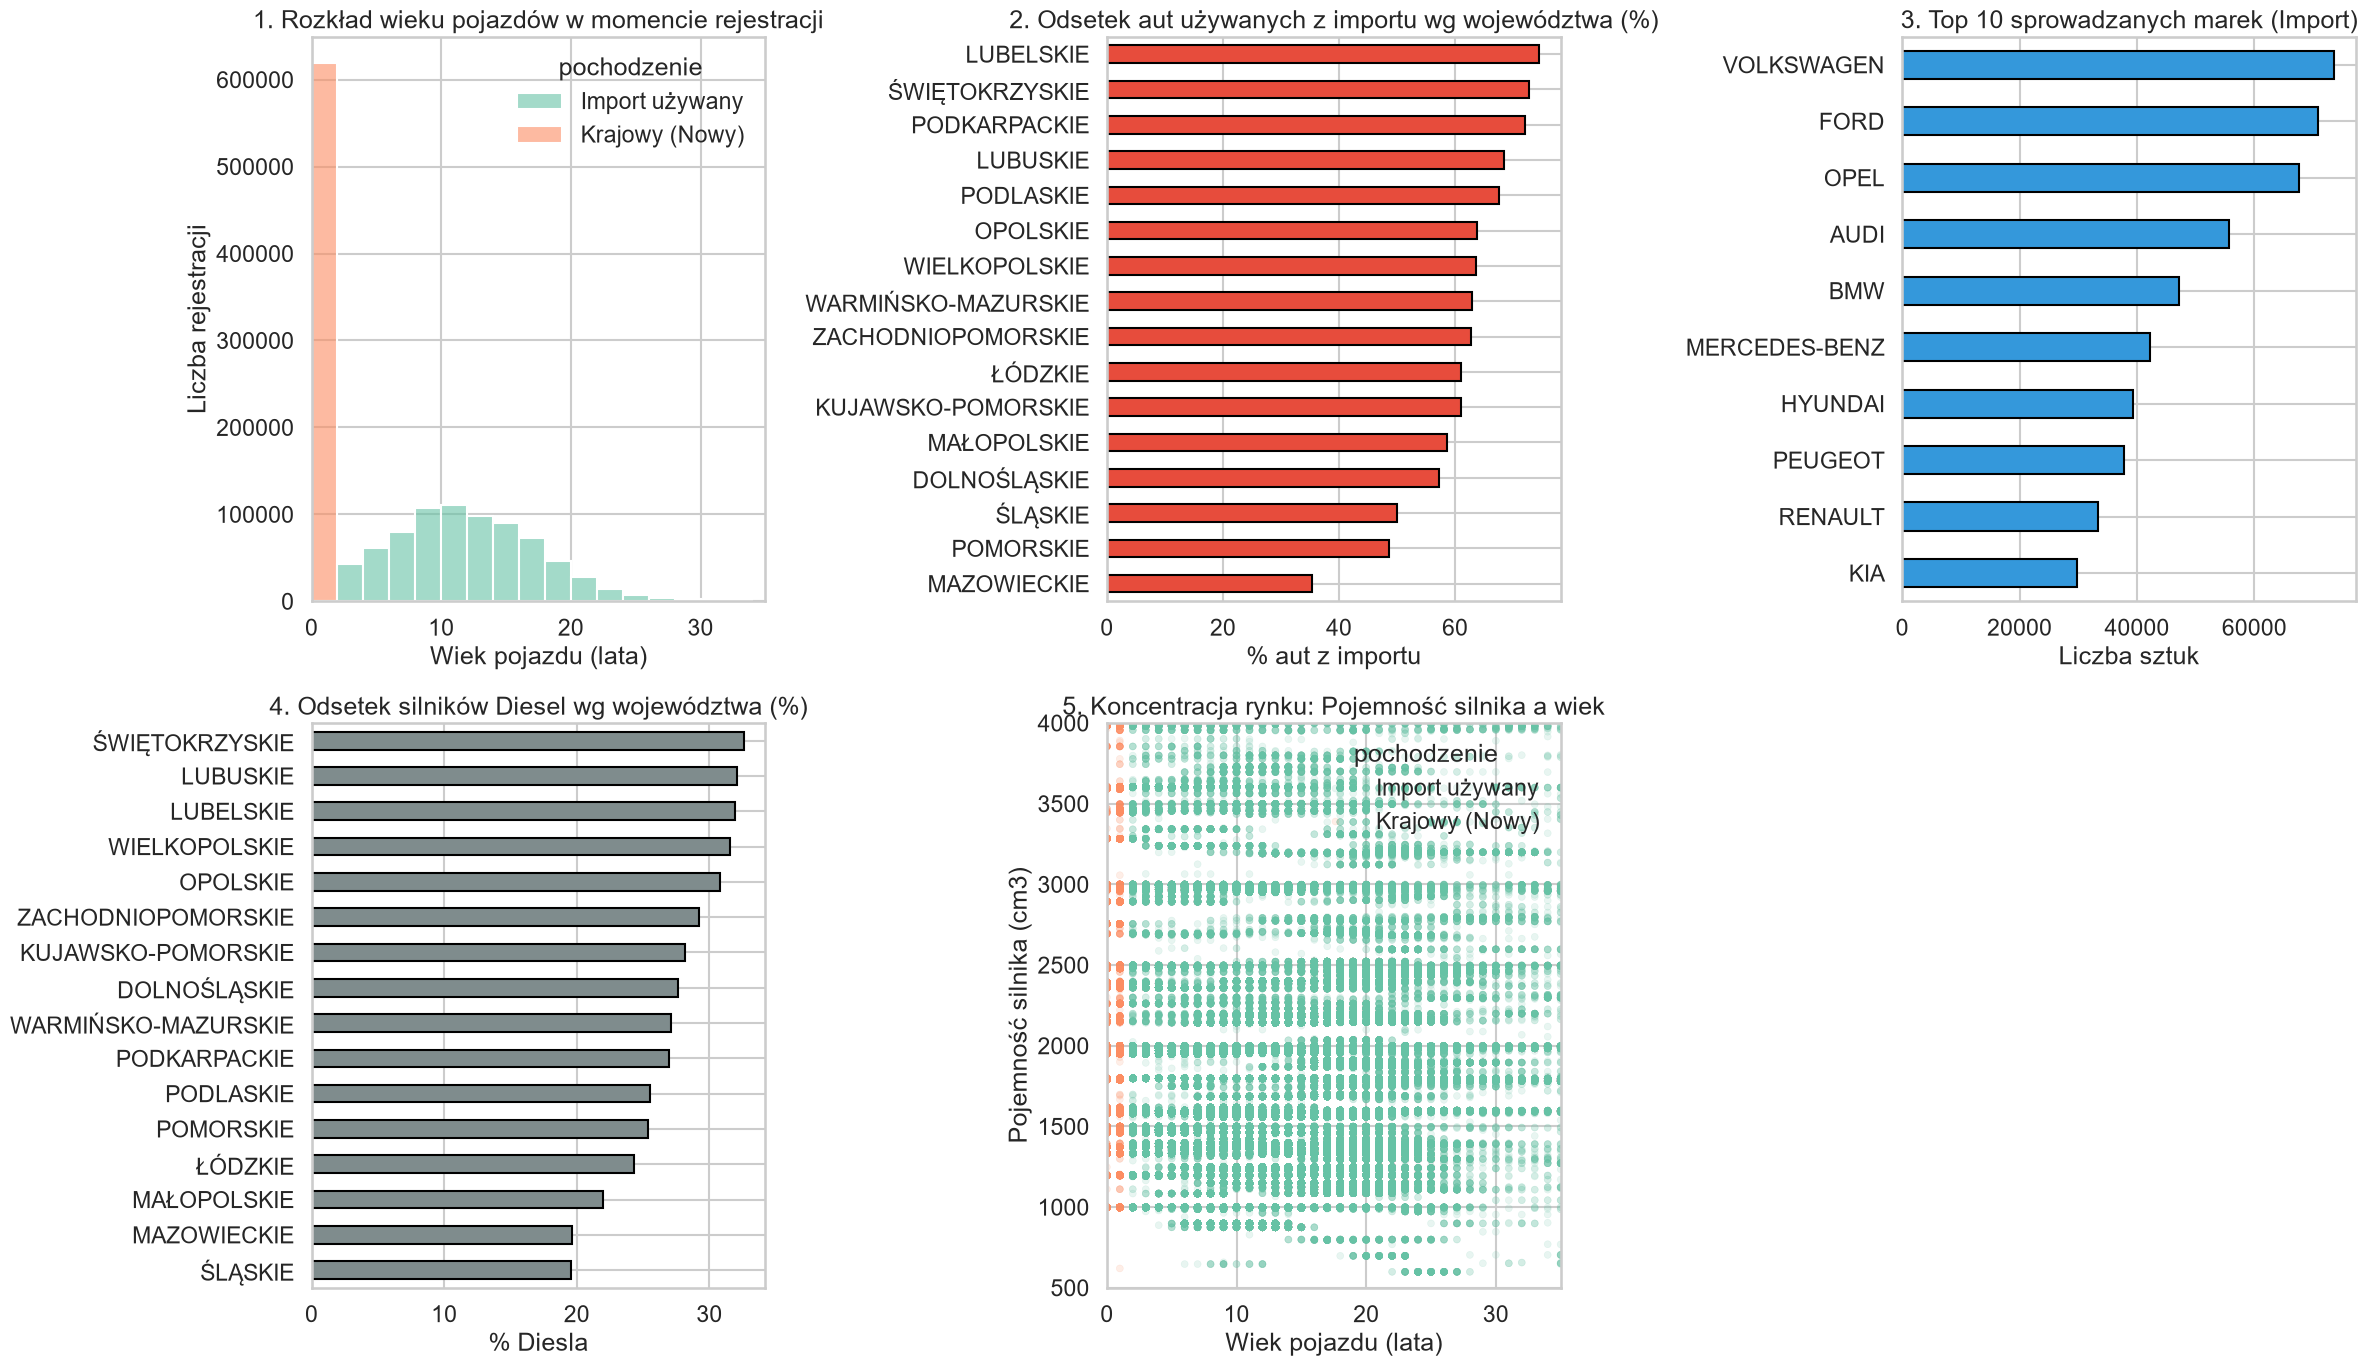

In [6]:
sns.set_theme(style="whitegrid", context="talk")
fig, axes = plt.subplots(2, 3, figsize=(24, 14))

# 1. Wiek pojazdów - Czytelny histogram warstwowy
sns.histplot(
    data=df_clean, x='wiek_pojazdu', hue='pochodzenie',
    multiple="layer", bins=range(0, 36, 2), alpha=0.6, ax=axes[0, 0], palette="Set2"
)
axes[0, 0].set_title("1. Rozkład wieku pojazdów w momencie rejestracji")
axes[0, 0].set_xlabel("Wiek pojazdu (lata)")
axes[0, 0].set_ylabel("Liczba rejestracji")
axes[0, 0].set_xlim(0, 35)

# 2. Udział aut z importu wg województw
import_share = df_clean.assign(is_import=df_clean['pochodzenie'] == 'Import używany') \
                       .groupby('rejestracja-wojewodztwo')['is_import'].mean().sort_values() * 100
import_share.plot(kind='barh', color='#e74c3c', edgecolor='black', ax=axes[0, 1])
axes[0, 1].set_title("2. Odsetek aut używanych z importu wg województwa (%)")
axes[0, 1].set_xlabel("% aut z importu")
axes[0, 1].set_ylabel("")

# 3. Najpopularniejsze marki na rynku wtórnym (Import)
top_import_brands = df_clean[df_clean['pochodzenie'] == 'Import używany']['marka'].value_counts().head(10).sort_values()
top_import_brands.plot(kind='barh', color='#3498db', edgecolor='black', ax=axes[0, 2])
axes[0, 2].set_title("3. Top 10 sprowadzanych marek (Import)")
axes[0, 2].set_xlabel("Liczba sztuk")
axes[0, 2].set_ylabel("")

# 4. Udział Diesla w województwach
diesel_share = df_clean.assign(is_diesel=df_clean['Naped'] == 'Diesel') \
                       .groupby('rejestracja-wojewodztwo')['is_diesel'].mean().sort_values() * 100
diesel_share.plot(kind='barh', color='#7f8c8d', edgecolor='black', ax=axes[1, 0])
axes[1, 0].set_title("4. Odsetek silników Diesel wg województwa (%)")
axes[1, 0].set_xlabel("% Diesla")
axes[1, 0].set_ylabel("")

# 5. Pojemność silnika a wiek - Zoptymalizowany Scatterplot
sns.scatterplot(
    data=df_clean, x='wiek_pojazdu', y='pojemnosc-skokowa-silnika',
    hue='pochodzenie', alpha=0.15, s=25, edgecolor=None, ax=axes[1, 1], palette="Set2"
)
axes[1, 1].set_title("5. Koncentracja rynku: Pojemność silnika a wiek")
axes[1, 1].set_xlabel("Wiek pojazdu (lata)")
axes[1, 1].set_ylabel("Pojemność silnika (cm3)")
axes[1, 1].set_xlim(0, 35)
axes[1, 1].set_ylim(500, 4000)

# Ukrycie 6 okna
axes[1, 2].axis('off')

plt.tight_layout()
plt.savefig("eda_klient_raport_final.png", dpi=150)
plt.show()

In [7]:
# Przygotowanie macierzy cech dla województw
woj_stats = df_clean.groupby('rejestracja-wojewodztwo').agg(
    sredni_wiek=('wiek_pojazdu', 'mean'),
    mediana_masy=('masa-wlasna', 'median'),
    proc_import=('pochodzenie', lambda x: (x == 'Import używany').mean() * 100),
    proc_diesel=('Naped', lambda x: (x == 'Diesel').mean() * 100),
    proc_ev=('Naped', lambda x: (x == 'Elektryczny (BEV)').mean() * 100)
).fillna(0)

# Oddzielenie "Hubów leasingowych", które zaburzały K-Means
outliers = ['MAZOWIECKIE', 'WIELKOPOLSKIE']
woj_normal = woj_stats.drop(index=[o for o in outliers if o in woj_stats.index])
woj_leasing = woj_stats.loc[[o for o in outliers if o in woj_stats.index]]

# Skalowanie cech tylko dla normalnych rynków
scaler = StandardScaler()
woj_scaled = scaler.fit_transform(woj_normal)

# Klasteryzacja na 3 grupy
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
woj_normal['Klaster'] = kmeans.fit_predict(woj_scaled)

print("\n--- WYNIKI KLASTERYZACJI (PROFILE REGIONALNE) ---")

for k in range(3):
    wojewodztwa = woj_normal[woj_normal['Klaster'] == k].index.tolist()
    print(f"\nKlaster {k}: {', '.join(wojewodztwa)}")
    display(woj_normal[woj_normal['Klaster'] == k].mean().round(2))

print("\n--- RYNKI SPECYFICZNE (WYŁĄCZONE Z KLASTERYZACJI - EFEKT LEASINGU) ---")
print(", ".join(woj_leasing.index.tolist()))
display(woj_leasing.mean().round(2))


--- WYNIKI KLASTERYZACJI (PROFILE REGIONALNE) ---

Klaster 0: DOLNOŚLĄSKIE, KUJAWSKO-POMORSKIE, LUBUSKIE, OPOLSKIE, PODKARPACKIE, PODLASKIE, WARMIŃSKO-MAZURSKIE, ŚWIĘTOKRZYSKIE


sredni_wiek        8.18
mediana_masy    1467.25
proc_import       65.70
proc_diesel       28.86
proc_ev            0.03
Klaster            0.00
dtype: float64


Klaster 1: MAŁOPOLSKIE, POMORSKIE, ŁÓDZKIE, ŚLĄSKIE


sredni_wiek        6.47
mediana_masy    1463.50
proc_import       54.54
proc_diesel       22.79
proc_ev            0.05
Klaster            1.00
dtype: float64


Klaster 2: LUBELSKIE, ZACHODNIOPOMORSKIE


sredni_wiek        8.66
mediana_masy    1487.50
proc_import       68.63
proc_diesel       30.58
proc_ev            0.13
Klaster            2.00
dtype: float64


--- RYNKI SPECYFICZNE (WYŁĄCZONE Z KLASTERYZACJI - EFEKT LEASINGU) ---
MAZOWIECKIE, WIELKOPOLSKIE


sredni_wiek        5.88
mediana_masy    1476.00
proc_import       49.49
proc_diesel       25.58
proc_ev            0.05
dtype: float64